# 01 — Data Understanding

This notebook defines the H&M fashion-demand problem and audits the source data before modelling. The unit of analysis for supervised learning is an **article-week**: information available by the end of week *t* is used to predict recorded sales in week *t+1*. Recorded sales are an observable proxy, not latent demand, because stock availability and unmet demand are not provided.

## Project tasks

- **Regression:** predict next-week recorded units for each eligible article-week.
- **Classification:** predict whether next-week recorded sales meet a high-demand threshold learned from training data.
- **Unsupervised learning:** identify article segments from product attributes and historical commercial behaviour.

## Testable hypotheses

1. Recent sales and rolling demand summaries contain predictive information about next-week sales.
2. Product category, price, and channel mix add signal beyond recent demand alone.
3. Demand prevalence and predictor distributions change over time, making chronological validation necessary.
4. Articles form interpretable groups with different demand levels, regularity, trends, and product characteristics.

The original H&M competition addressed personalised recommendation. This project instead studies aggregate recorded sales by article and week.

## 1. Source inventory and reproducibility

The three principal sources are transactions, article metadata, and customer metadata. Customer attributes are optional for modelling and must only be aggregated through past transactions if used. The audit reads transactions in chunks so that the full file does not need to fit in memory.

In [1]:
from pathlib import Path
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "src/data/process_data.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the fashion-demand-ml project.")
sys.path.insert(0, str(ROOT))
import importlib
import src.visualization.style as chart_style
importlib.reload(chart_style)
from src.visualization.style import (
    BLUE, GRID, INK, apply_style, display_es, es, format_number, format_percent, add_source, add_title,
)
apply_style()

RAW_DIR = ROOT / "data/raw"
SOURCE_PATHS = {
    "transactions": RAW_DIR / "transactions_train.csv",
    "articles": RAW_DIR / "articles.csv",
    "customers": RAW_DIR / "customers.csv",
}
missing_sources = [name for name, path in SOURCE_PATHS.items() if not path.is_file()]
if missing_sources:
    raise FileNotFoundError(f"Missing required source files: {missing_sources}")

source_inventory = pd.DataFrame([
    {"source": name, "file": path.name, "size_gb": path.stat().st_size / 1024**3}
    for name, path in SOURCE_PATHS.items()
]).set_index("source")
display_es(source_inventory.round({"size_gb": 3}))

,file,size_gb
source,,
transactions,transactions_train.csv,"3,248"
articles,articles.csv,"0,034"
customers,customers.csv,"0,193"


## 2. Schemas, identifiers, and source granularity

`transactions_train.csv` is event-level and may contain repeated-looking rows that represent multiple purchased units. `articles.csv` must contain one row per `article_id`, while `customers.csv` must contain one row per `customer_id`. Identifiers are loaded as strings so that leading zeros are preserved.

In [2]:
articles = pd.read_csv(
    SOURCE_PATHS["articles"],
    dtype={"article_id": "string", "product_code": "string"},
)
customers = pd.read_csv(
    SOURCE_PATHS["customers"],
    dtype={"customer_id": "string"},
)

reference_summary = pd.DataFrame({
    "rows": [len(articles), len(customers)],
    "columns": [articles.shape[1], customers.shape[1]],
    "duplicate_primary_keys": [
        articles["article_id"].duplicated().sum(),
        customers["customer_id"].duplicated().sum(),
    ],
    "missing_primary_keys": [
        articles["article_id"].isna().sum(),
        customers["customer_id"].isna().sum(),
    ],
}, index=["articles", "customers"])
display_es(reference_summary)
display_es(pd.DataFrame({
    "article_dtype": articles.dtypes.astype(str),
    "article_missing": articles.isna().sum(),
}).sort_values("article_missing", ascending=False))
display_es(pd.DataFrame({
    "customer_dtype": customers.dtypes.astype(str),
    "customer_missing": customers.isna().sum(),
}).sort_values("customer_missing", ascending=False))
display_es(articles.head(3))
display_es(customers.head(3))

,rows,columns,duplicate_primary_keys,missing_primary_keys
articles,105.542,25,0,0
customers,1.371.980,7,0,0


,article_dtype,article_missing
detail_desc,object,416
product_code,string,0
prod_name,object,0
product_type_no,int64,0
product_type_name,object,0
product_group_name,object,0
graphical_appearance_no,int64,0
graphical_appearance_name,object,0
article_id,string,0
colour_group_code,int64,0


,customer_dtype,customer_missing
Active,float64,907.576
FN,float64,895.050
fashion_news_frequency,object,16.011
age,float64,15.861
club_member_status,object,6.062
customer_id,string,0
postal_code,object,0


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,0108775015,0108775,Strap top,253,Vest top,Garment Upper body,1.010.016,Solid,9,Black,4,Dark,5,Black,1.676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1.002,Jersey Basic,Jersey top with narrow shoulder straps.
1,0108775044,0108775,Strap top,253,Vest top,Garment Upper body,1.010.016,Solid,10,White,3,Light,9,White,1.676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1.002,Jersey Basic,Jersey top with narrow shoulder straps.
2,0108775051,0108775,Strap top (1),253,Vest top,Garment Upper body,1.010.017,Stripe,11,Off White,1,Dusty Light,9,White,1.676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1.002,Jersey Basic,Jersey top with narrow shoulder straps.


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3d25f88aa139fdfc657,—,—,ACTIVE,NONE,49,52043ee2162cf5aa7ee79974281641c6f11a68d276429a91f8ca0d4b6efa8100
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051eec9c12fb36984420fa,—,—,ACTIVE,NONE,25,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93f4c830291c32bc3057
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,—,—,ACTIVE,NONE,24,64f17e6a330a85798e4998f62d0930d14db8db1c054af6c9090f7dd3e38380dc


## 3. Full transaction audit

The following pass checks the complete transaction source in bounded-memory chunks. It measures temporal coverage, required-field missingness, price and channel validity, referential integrity, ordering, and weekly transaction volume. Exact-looking duplicate rows are reported but not removed because they may represent multiple units purchased by the same customer.

In [3]:
TRANSACTION_COLUMNS = ["t_dat", "customer_id", "article_id", "price", "sales_channel_id"]
CHUNK_SIZE = 1_000_000
known_articles = set(articles["article_id"].dropna())
known_customers = set(customers["customer_id"].dropna())

audit = {
    "rows": 0, "missing_required_fields": 0, "invalid_dates": 0,
    "negative_or_nonfinite_prices": 0, "invalid_channels": 0,
    "unknown_articles": 0, "unknown_customers": 0,
    "within_chunk_identical_rows_lower_bound": 0, "ordering_violations": 0,
}
weekly_parts = []
transaction_sample = None
first_date = last_date = previous_last_date = None
observed_article_ids = set()

for chunk_number, chunk in enumerate(pd.read_csv(
        SOURCE_PATHS["transactions"], usecols=TRANSACTION_COLUMNS, chunksize=CHUNK_SIZE,
        dtype={"t_dat": "string", "customer_id": "string",
               "article_id": "string", "price": "float64",
               "sales_channel_id": "Int64"}), 1):
    if transaction_sample is None:
        transaction_sample = chunk.head(5).copy()
    audit["rows"] += len(chunk)
    audit["missing_required_fields"] += int(chunk.isna().sum().sum())
    dates = pd.to_datetime(chunk["t_dat"], format="%Y-%m-%d", errors="coerce")
    audit["invalid_dates"] += int(dates.isna().sum())
    valid_dates = dates.dropna()
    if not valid_dates.empty:
        chunk_first, chunk_last = valid_dates.iloc[0], valid_dates.iloc[-1]
        first_date = chunk_first if first_date is None else min(first_date, valid_dates.min())
        last_date = chunk_last if last_date is None else max(last_date, valid_dates.max())
        if not valid_dates.is_monotonic_increasing or (previous_last_date is not None and chunk_first < previous_last_date):
            audit["ordering_violations"] += 1
        previous_last_date = chunk_last
        weeks = valid_dates - pd.to_timedelta(valid_dates.dt.weekday, unit="D")
        weekly_parts.append(weeks.value_counts().sort_index())
    audit["negative_or_nonfinite_prices"] += int((chunk["price"].lt(0) | ~np.isfinite(chunk["price"])).sum())
    audit["invalid_channels"] += int((~chunk["sales_channel_id"].isin([1, 2])).sum())
    audit["unknown_articles"] += int((~chunk["article_id"].isin(known_articles)).sum())
    audit["unknown_customers"] += int((~chunk["customer_id"].isin(known_customers)).sum())
    audit["within_chunk_identical_rows_lower_bound"] += int(chunk.duplicated(TRANSACTION_COLUMNS).sum())
    observed_article_ids.update(chunk["article_id"].dropna().unique())

weekly_transactions = pd.concat(weekly_parts, axis=1).fillna(0).sum(axis=1).sort_index().astype("int64")
transaction_audit = pd.Series({
    **audit,
    "first_date": first_date.date(),
    "last_date": last_date.date(),
    "calendar_days": (last_date - first_date).days + 1,
    "observed_articles": len(observed_article_ids),
    "catalogue_articles_without_transactions": len(known_articles - observed_article_ids),
})
display_es(transaction_sample)
display_es(transaction_audit.to_frame("value"))

,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,0663713001,"0,0508305084745762",2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,0541518023,"0,0304915254237288",2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,0505221004,"0,0152372881355932",2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,0685687003,"0,0169322033898305",2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,0685687004,"0,0169322033898305",2


,value
rows,31.788.324
missing_required_fields,0
invalid_dates,0
negative_or_nonfinite_prices,0
invalid_channels,0
unknown_articles,0
unknown_customers,0
within_chunk_identical_rows_lower_bound,2.974.904
ordering_violations,0
first_date,2018-09-20


## 4. Temporal coverage and product composition

Weekly transaction counts reveal changes in observed commercial activity, but do not by themselves distinguish changes in demand, catalogue exposure, stock, promotions, or data collection. The product table is also reviewed at several category levels before choosing metadata for modelling.

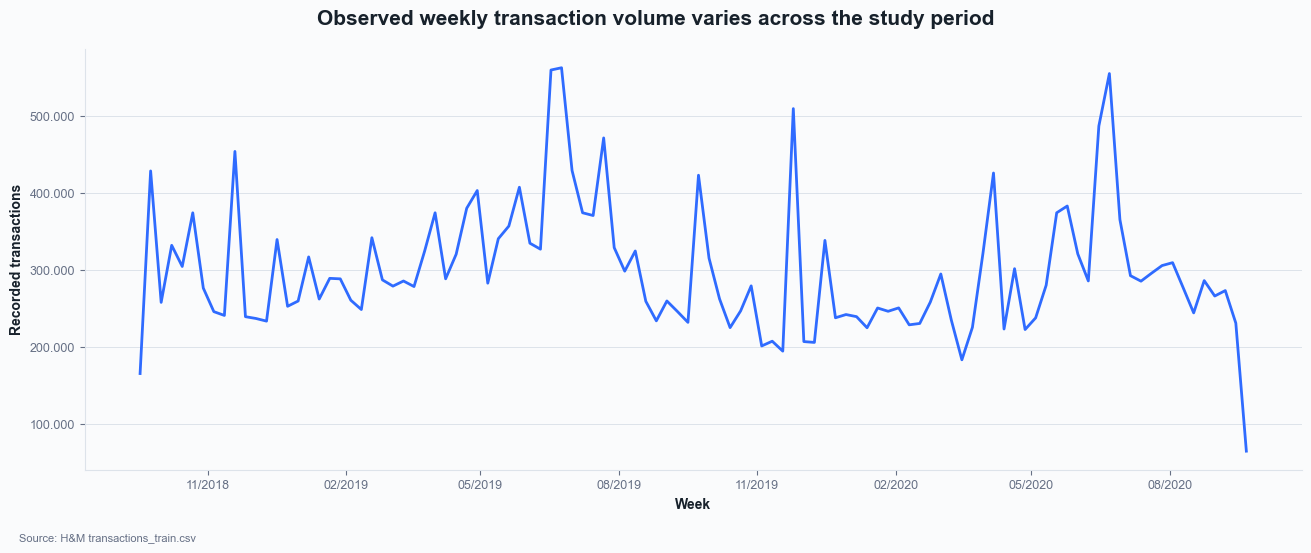

In [4]:
fig, ax = plt.subplots(figsize=(13, 5.5), layout="constrained")
ax.plot(weekly_transactions.index, weekly_transactions.values, color=BLUE, linewidth=2)
add_title(fig, "Observed weekly transaction volume varies across the study period")
ax.set_xlabel("Week", fontweight="bold", color=INK)
ax.set_ylabel("Recorded transactions", fontweight="bold", color=INK)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.grid(axis="y", color=GRID, linewidth=.7)
ax.spines[["top", "right"]].set_visible(False)
add_source(fig, "Source: H&M transactions_train.csv")
plt.show()

category_summary = pd.concat({
    "product_group_name": articles["product_group_name"].value_counts(dropna=False).head(10),
    "index_group_name": articles["index_group_name"].value_counts(dropna=False).head(10),
    "garment_group_name": articles["garment_group_name"].value_counts(dropna=False).head(10),
}, names=["field", "category"]).rename("articles").to_frame()
display_es(category_summary)

## 5. Quality decisions and modelling implications

- Transaction rows represent recorded purchase events; identical rows are preserved unless independent evidence shows that they are erroneous.
- A zero may be assigned only for an article-week inside verified source coverage. It means no recorded sale, not confirmed availability.
- The article-week table must be constructed chronologically. Random splitting is inappropriate for the primary evaluation.
- Product categories with missing values should receive an explicit `Unknown` level rather than causing article loss.
- Customer attributes are optional. If used, they must be aggregated from transactions available before the prediction date.
- Article and customer identifiers are join keys, not continuous quantities.

## 6. Limitations and bias risks

The data do not provide stock levels, replenishment, marketing exposure, returns, margins, or unmet demand. Recorded sales may therefore be censored by availability and influenced by mechanisms absent from the model. The candidate policy also focuses on articles sold in the current week, so conclusions do not automatically extend to new or currently inactive products. Customer and product composition can change over time, and aggregate accuracy may conceal weak performance for rare categories or high-demand periods. Associations found in this observational dataset must not be presented as causal effects.

## 7. Related material

- H&M Group, *H&M Personalized Fashion Recommendations* dataset and competition documentation.
- Hyndman and Athanasopoulos, *Forecasting: Principles and Practice*, for time-ordered forecasting evaluation.
- Kuhn and Johnson, *Applied Predictive Modeling*, for supervised modelling and resampling design.
- scikit-learn documentation on time-series splitting, pipelines, permutation importance, and clustering metrics.

## Conclusion

The sources support an article-week study of recorded sales, provided that complete weeks, chronological feature construction, stable join keys, and the distinction between sales and latent demand are enforced. Notebook `02_data_preparation.ipynb` implements and verifies that contract.